# Caderno de Estudo e Simulação: Arquitetura da Rede Neural e Laço de Treinamento

> **Objetivo:** Este caderno serve como laboratório interativo para dissecar o funcionamento da classe `RedeNeural` (`mlp/rede.py`). Abordamos a composição sequencial de camadas, a comparação empírica dos regimes de otimização (Batch vs. Mini-batch vs. Pure SGD), a capacidade de separação não-linear através de superfícies de decisão 2D e o diagnóstico de curvas de aprendizado (treino vs. validação).
>


In [1]:
import sys
from pathlib import Path

# Configuração do caminho raiz do projeto
raiz_projeto = Path.cwd().resolve()
while raiz_projeto.name != "projeto-final-mlp" and raiz_projeto.parent != raiz_projeto:
    raiz_projeto = raiz_projeto.parent
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Estilização visual dos gráficos
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 120

from mlp.rede import RedeNeural
from mlp.camadas import Densa
from mlp.ativacoes import Sigmoide, LeakyReLU, Swish
from mlp.custos import MSE, BCE

print("Ambiente configurado com sucesso!")
print(f"NumPy versão: {np.__version__}")
print(f"Raiz do projeto: {raiz_projeto}")


Ambiente configurado com sucesso!
NumPy versão: 1.26.4
Raiz do projeto: /home/luizeduardo/_dev/faculdade/aprendizado_maquinas/projeto-final-mlp


## 1. Encadeamento Sequencial e Fluxo de Tensores no Grafo

A classe `RedeNeural` conecta modularmente instâncias de `Camada` e `Ativacao`:

$$X \xrightarrow{\text{Densa}_1} Z^{[1]} \xrightarrow{f_1} A^{[1]} \xrightarrow{\text{Densa}_2} Z^{[2]} \xrightarrow{f_2} A^{[2]} \dots \xrightarrow{f_L} \hat{y}$$

### Propagação Direta (`passo_a_frente`):
Cada camada recebe a saída da anterior como entrada e armazena internamente os tensores necessários para a retropropagação (como $X$ no caso de `Densa` e $Z$ no caso de `Ativacao`).

### Retropropagação (`passo_atras`):
O gradiente da função de custo em relação à saída final, $\delta^{[L]} = \dfrac{\partial L}{\partial \hat{y}}$, é propagado em ordem estritamente reversa (`reversed(self.camadas)`), aplicando a regra da cadeia sequencialmente.


In [2]:
# Demonstração do fluxo dimensional em uma rede multicamadas
rng = np.random.RandomState(42)

rede = RedeNeural(semente_aleatoria=42)
rede.adicionar(Densa(dimensao_entrada=4, dimensao_saida=6, gerador_aleatorio=rng))
rede.adicionar(LeakyReLU())
rede.adicionar(Densa(dimensao_entrada=6, dimensao_saida=3, gerador_aleatorio=rng))
rede.adicionar(Swish())
rede.adicionar(Densa(dimensao_entrada=3, dimensao_saida=1, gerador_aleatorio=rng))
rede.adicionar(Sigmoide())

# Entrada sintética de teste com batch de 5 amostras
X_exemplo = rng.randn(5, 4)

print("--- FLUXO DE CAMADAS NA REDE NEURAL ---")
tensor_atual = X_exemplo
print(f"Entrada inicial X: formato {tensor_atual.shape}")

for i, camada in enumerate(rede.camadas):
    tensor_atual = camada.passo_a_frente(tensor_atual)
    tipo_camada = type(camada).__name__
    print(f"Camada {i+1:02d} ({tipo_camada:10s}) -> Saída formato: {tensor_atual.shape}")

# Comparando saída de passo_a_frente com predizer
y_pred = rede.predizer(X_exemplo)
print(f"\nPredição final (probabilidade [0, 1]):\n{y_pred.flatten().round(4)}")
print(f"Consistência entre passo_a_frente e predizer: {np.allclose(tensor_atual, y_pred)}")


--- FLUXO DE CAMADAS NA REDE NEURAL ---
Entrada inicial X: formato (5, 4)
Camada 01 (Densa     ) -> Saída formato: (5, 6)
Camada 02 (LeakyReLU ) -> Saída formato: (5, 6)
Camada 03 (Densa     ) -> Saída formato: (5, 3)
Camada 04 (Swish     ) -> Saída formato: (5, 3)
Camada 05 (Densa     ) -> Saída formato: (5, 1)
Camada 06 (Sigmoide  ) -> Saída formato: (5, 1)

Predição final (probabilidade [0, 1]):
[0.5054 0.3834 0.4135 0.4998 0.4798]
Consistência entre passo_a_frente e predizer: True


## 2. Comparativo dos Regimes de Otimização: Batch vs. Mini-batch vs. Pure SGD

O tamanho do lote ($B$) define a dinâmica do algoritmo de gradiente descendente:

1. **Batch Gradient Descent ($B = N$):** utiliza todo o conjunto de dados em cada atualização. O gradiente é determinístico e exato, mas a computação é lenta e a trajetória pode estagnar facilmente em platôs ou mínimos locais rasos.
2. **Pure Stochastic Gradient Descent ($B = 1$):** atualiza os pesos a cada amostra isolada. Extremamente ruidoso e perde a eficiência de vetorização do NumPy, com oscilações intensas.
3. **Mini-batch SGD ($1 < B < N$, ex.: 16 ou 32):** combina a vetorização matricial eficiente do NumPy com um nível ideal de ruído estocástico que auxilia na exploração da superfície de perda.

Abaixo, comparamos o comportamento da perda ao longo do treinamento para os três regimes.


Full Batch (B=120)   -> Custo Inicial: 16.7246 | Custo Final: 3.8632e-02
Mini-batch (B=16)    -> Custo Inicial: 2.8413 | Custo Final: 3.3393e-02
Pure SGD (B=1)       -> Custo Inicial: 0.0433 | Custo Final: 3.7742e-02


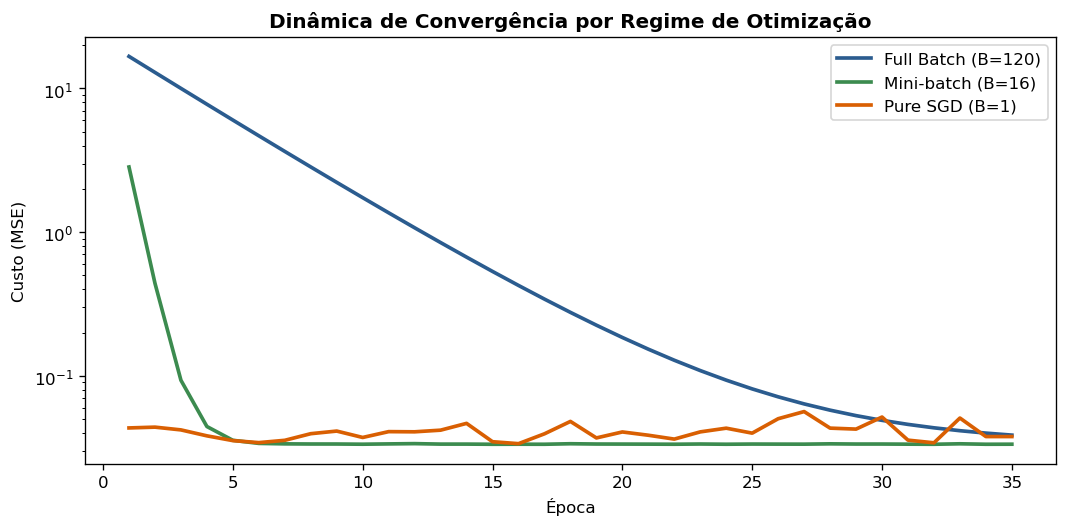

In [3]:
# Criação de um conjunto sintético de regressão com ruído
rng_reg = np.random.RandomState(10)
N = 120
X_dados = rng_reg.uniform(-2, 2, size=(N, 2))
W_true = np.array([[2.5], [-1.8]])
b_true = np.array([[0.5]])
y_dados = X_dados @ W_true + b_true + rng_reg.normal(0, 0.2, size=(N, 1))

# Comparação de tamanhos de lote: Full Batch, Mini-batch e Pure SGD
configuracoes = [
    ("Full Batch (B=120)", 120, "#2b5c8f"),
    ("Mini-batch (B=16)", 16, "#3c8b4f"),
    ("Pure SGD (B=1)", 1, "#d95f02"),
]

epocas_comp = 35
lr_comp = 0.05
historicos_comp = {}

for rotulo, tam_lote, cor in configuracoes:
    r = RedeNeural(semente_aleatoria=42)
    r.adicionar(Densa(2, 1, gerador_aleatorio=np.random.RandomState(42)))
    r.compilar(MSE())
    hist = r.treinar(X_dados, y_dados, epocas=epocas_comp, taxa_aprendizagem=lr_comp, tamanho_lote=tam_lote, verbal=False)
    historicos_comp[rotulo] = (hist["custo_treino"], cor)

# Plot comparativo de convergência
fig, ax = plt.subplots(figsize=(9, 4.5))

for rotulo, (perdas, cor) in historicos_comp.items():
    ax.plot(range(1, epocas_comp + 1), perdas, label=rotulo, color=cor, linewidth=2.2)

ax.set_title("Dinâmica de Convergência por Regime de Otimização", fontweight="bold")
ax.set_xlabel("Época")
ax.set_ylabel("Custo (MSE)")
ax.set_yscale("log")
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

for rotulo, (perdas, _) in historicos_comp.items():
    print(f"{rotulo:20s} -> Custo Inicial: {perdas[0]:.4f} | Custo Final: {perdas[-1]:.4e}")


## 3. Classificação Não-Linear e Superfície de Decisão 2D

Um classificador linear simples só consegue traçar retas ou hiperplanos de separação. Quando os dados possuem geometria circular concêntrica ou estruturas complexas, um modelo linear falha completamente.

Ao empilhar camadas densas com funções de ativação não-lineares, a rede neural deforma o espaço de características (*feature space*), tornando os dados linearmente separáveis nas camadas finais.

Abaixo, treinamos uma rede MLP de 3 camadas no problema dos **círculos concêntricos** e visualizamos a superfície de decisão resultante.


Custo Inicial: 0.6498 -> Custo Final: 0.0017
Acurácia de Classificação nos Dados de Treino: 100.0%


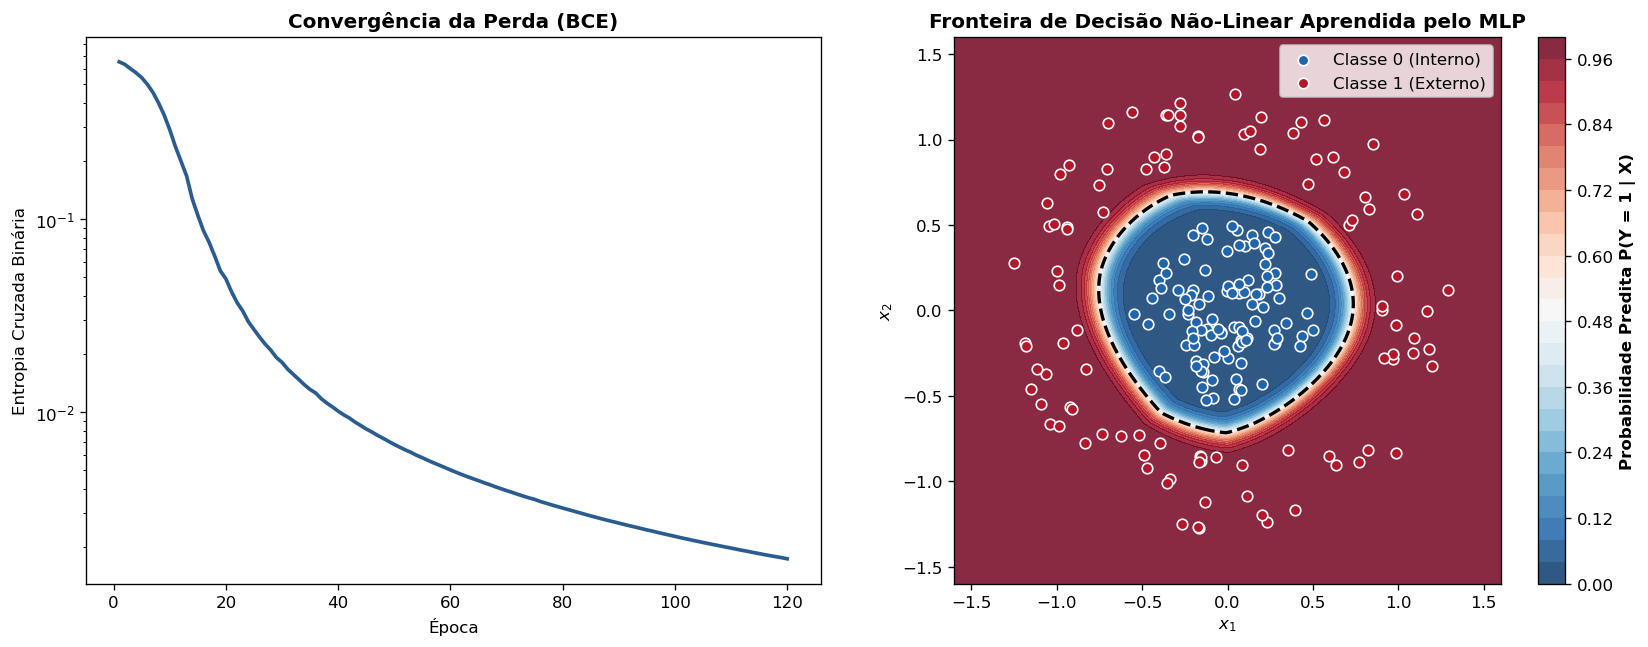

In [4]:
# Geração do problema dos Círculos Concêntricos
rng_circ = np.random.RandomState(99)
N_circ = 200

# Classe 0 (Círculo interno, raio ~ 0.5)
raio_0 = rng_circ.uniform(0.1, 0.55, size=(N_circ // 2, 1))
ang_0 = rng_circ.uniform(0, 2 * np.pi, size=(N_circ // 2, 1))
X_0 = np.hstack([raio_0 * np.cos(ang_0), raio_0 * np.sin(ang_0)])
y_0 = np.zeros((N_circ // 2, 1))

# Classe 1 (Círculo externo, raio ~ 0.95)
raio_1 = rng_circ.uniform(0.85, 1.3, size=(N_circ // 2, 1))
ang_1 = rng_circ.uniform(0, 2 * np.pi, size=(N_circ // 2, 1))
X_1 = np.hstack([raio_1 * np.cos(ang_1), raio_1 * np.sin(ang_1)])
y_1 = np.ones((N_circ // 2, 1))

X_circ = np.vstack([X_0, X_1])
y_circ = np.vstack([y_0, y_1])

# Construção da Rede MLP: 2 -> 12 (Swish) -> 6 (LeakyReLU) -> 1 (Sigmoide)
rede_circ = RedeNeural(semente_aleatoria=42)
rede_circ.adicionar(Densa(2, 12, gerador_aleatorio=np.random.RandomState(42)))
rede_circ.adicionar(Swish())
rede_circ.adicionar(Densa(12, 6, gerador_aleatorio=np.random.RandomState(42)))
rede_circ.adicionar(LeakyReLU())
rede_circ.adicionar(Densa(6, 1, gerador_aleatorio=np.random.RandomState(42)))
rede_circ.adicionar(Sigmoide())
rede_circ.compilar(BCE())

# Treinamento com Mini-batch SGD
hist_circ = rede_circ.treinar(
    X_circ, y_circ, epocas=120, taxa_aprendizagem=0.15, tamanho_lote=16, verbal=False
)

# Geração da grade para plot da superfície de decisão contínua
x_min, x_max = -1.6, 1.6
y_min, y_max = -1.6, 1.6
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
grid_teste = np.column_stack([xx.ravel(), yy.ravel()])
probabilidades = rede_circ.predizer(grid_teste).reshape(xx.shape)

# Visualização gráfica da Fronteira de Decisão
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Curva de Perda BCE
axes[0].plot(range(1, len(hist_circ["custo_treino"]) + 1), hist_circ["custo_treino"], color="#2b5c8f", linewidth=2.2)
axes[0].set_title("Convergência da Perda (BCE)", fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Entropia Cruzada Binária")
axes[0].set_yscale("log")

# 2. Superfície e Fronteira de Decisão 2D
cont = axes[1].contourf(xx, yy, probabilidades, levels=25, cmap="RdBu_r", alpha=0.85)
cbar = plt.colorbar(cont, ax=axes[1])
cbar.set_label("Probabilidade Predita P(Y = 1 | X)", fontweight="bold")

# Linha de decisão no limiar 0.5
axes[1].contour(xx, yy, probabilidades, levels=[0.5], colors="black", linewidths=2.0, linestyles="--")

# Pontos de treinamento
axes[1].scatter(X_0[:, 0], X_0[:, 1], color="#2166ac", edgecolors="white", s=40, label="Classe 0 (Interno)")
axes[1].scatter(X_1[:, 0], X_1[:, 1], color="#b2182b", edgecolors="white", s=40, label="Classe 1 (Externo)")

axes[1].set_title("Fronteira de Decisão Não-Linear Aprendida pelo MLP", fontweight="bold")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
axes[1].set_aspect("equal")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

# Acurácia de treino
predicoes_finais = (rede_circ.predizer(X_circ) >= 0.5).astype(int)
acuracia = np.mean(predicoes_finais == y_circ) * 100
print(f"Custo Inicial: {hist_circ['custo_treino'][0]:.4f} -> Custo Final: {hist_circ['custo_treino'][-1]:.4f}")
print(f"Acurácia de Classificação nos Dados de Treino: {acuracia:.1f}%")


## 4. Monitoramento Simultâneo de Treino e Validação

Durante o treinamento real de modelos de Aprendizado de Máquina, o monitoramento exclusivo do custo de treino pode induzir a erros de avaliação: um modelo pode memorizar os dados de treino (*overfitting*) sem aprender a generalizar para amostras inéditas.

O método `treinar` aceita `X_validacao` e `y_validacao`, calculando o custo no conjunto de validação ao final de cada época sem alterar os gradientes nem os pesos da rede.

Abaixo, simulamos a divisão de um conjunto em treino (80%) e validação (20%) e plotamos as curvas simultâneas.


Custo Treino Inicial:    0.9106 -> Final: 0.0279
Custo Validação Inicial: 0.9392 -> Final: 0.0651


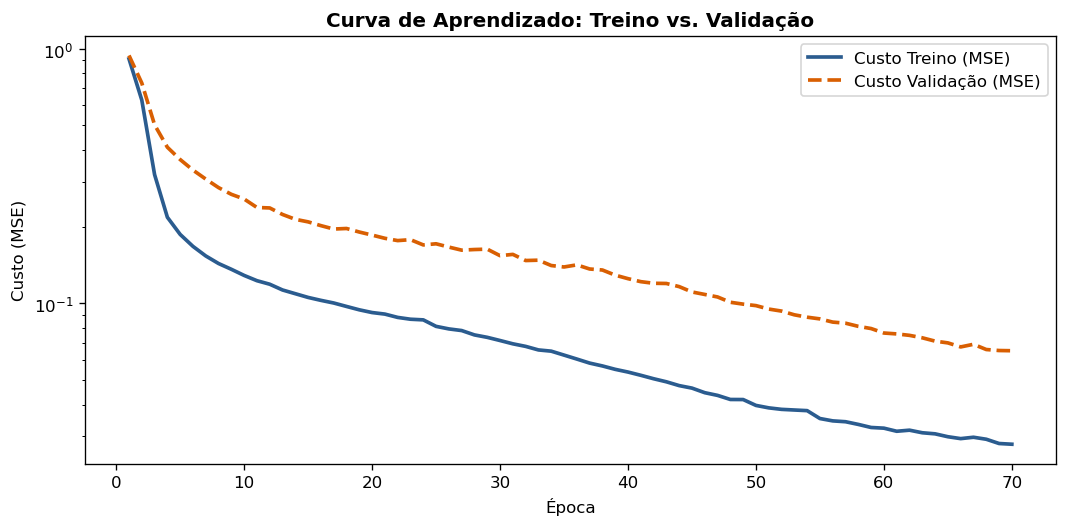

In [5]:
# Divisão sintética em Treino (80%) e Validação (20%)
rng_val = np.random.RandomState(77)
N_total = 200

X_full = rng_val.uniform(-2, 2, size=(N_total, 3))
y_full = np.sin(X_full[:, 0:1]) + 0.5 * X_full[:, 1:2] - 0.3 * (X_full[:, 2:3] ** 2)

indices = rng_val.permutation(N_total)
corte = int(0.8 * N_total)

X_train, y_train = X_full[indices[:corte]], y_full[indices[:corte]]
X_val, y_val = X_full[indices[corte:]], y_full[indices[corte:]]

# Rede para Regressão Não-Linear: 3 -> 8 (LeakyReLU) -> 4 (Swish) -> 1
rede_val = RedeNeural(semente_aleatoria=42)
rede_val.adicionar(Densa(3, 8, gerador_aleatorio=np.random.RandomState(42)))
rede_val.adicionar(LeakyReLU())
rede_val.adicionar(Densa(8, 4, gerador_aleatorio=np.random.RandomState(42)))
rede_val.adicionar(Swish())
rede_val.adicionar(Densa(4, 1, gerador_aleatorio=np.random.RandomState(42)))
rede_val.compilar(MSE())

# Treinamento com monitoramento
historico_val = rede_val.treinar(
    X_train, y_train, epocas=70, taxa_aprendizagem=0.04, tamanho_lote=16,
    X_validacao=X_val, y_validacao=y_val, verbal=False
)

# Visualização gráfica Treino vs Validação
fig, ax = plt.subplots(figsize=(9, 4.5))

epocas_eixo = range(1, len(historico_val["custo_treino"]) + 1)
ax.plot(epocas_eixo, historico_val["custo_treino"], label="Custo Treino (MSE)", color="#2b5c8f", linewidth=2.2)
ax.plot(epocas_eixo, historico_val["custo_validacao"], label="Custo Validação (MSE)", color="#d95f02", linewidth=2.2, linestyle="--")

ax.set_title("Curva de Aprendizado: Treino vs. Validação", fontweight="bold")
ax.set_xlabel("Época")
ax.set_ylabel("Custo (MSE)")
ax.set_yscale("log")
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

print(f"Custo Treino Inicial:    {historico_val['custo_treino'][0]:.4f} -> Final: {historico_val['custo_treino'][-1]:.4f}")
print(f"Custo Validação Inicial: {historico_val['custo_validacao'][0]:.4f} -> Final: {historico_val['custo_validacao'][-1]:.4f}")


## 5. Sensibilidade à Taxa de Aprendizagem ($\eta$)

A taxa de aprendizagem é o hiperparâmetro mais sensível do gradiente descendente:

- **$\eta$ muito baixo:** a rede converge de forma extremamente lenta, necessitando de centenas de épocas adicionais.
- **$\eta$ ideal:** a perda decresce suave e rapidamente em direção ao mínimo.
- **$\eta$ muito alto:** os passos no gradiente ultrapassam os vales da superfície (*overshooting*), provocando oscilações violentas ou até mesmo divergência numérica.

Abaixo, simulamos a mesma arquitetura treinada com três taxas de aprendizado distintas.


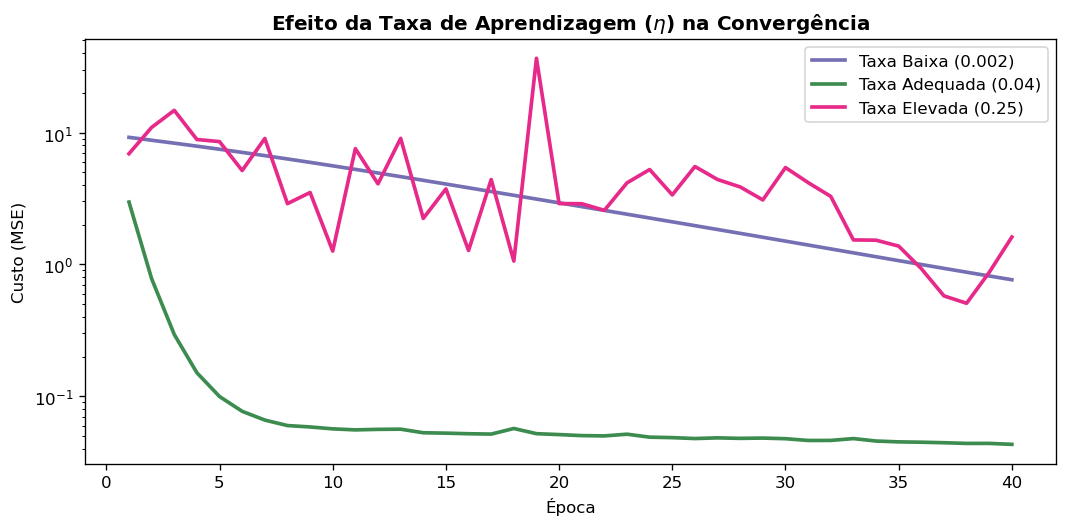

In [6]:
# Comparativo com diferentes taxas de aprendizado
taxas = [
    (0.002, "Taxa Baixa (0.002)", "#7570b3"),
    (0.04,  "Taxa Adequada (0.04)", "#3c8b4f"),
    (0.25,  "Taxa Elevada (0.25)", "#e7298a")
]

fig, ax = plt.subplots(figsize=(9, 4.5))

for lr, rotulo, cor in taxas:
    r_lr = RedeNeural(semente_aleatoria=42)
    r_lr.adicionar(Densa(2, 6, gerador_aleatorio=np.random.RandomState(42)))
    r_lr.adicionar(Swish())
    r_lr.adicionar(Densa(6, 1, gerador_aleatorio=np.random.RandomState(42)))
    r_lr.compilar(MSE())
    
    h_lr = r_lr.treinar(X_dados, y_dados, epocas=40, taxa_aprendizagem=lr, tamanho_lote=20, verbal=False)
    ax.plot(range(1, 41), h_lr["custo_treino"], label=rotulo, color=cor, linewidth=2.2)

ax.set_title("Efeito da Taxa de Aprendizagem ($\\eta$) na Convergência", fontweight="bold")
ax.set_xlabel("Época")
ax.set_ylabel("Custo (MSE)")
ax.set_yscale("log")
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()
